<a href="https://colab.research.google.com/github/JosiasG-dev/Analisis_de_Algoritmos/blob/main/JOSIAS_ALONZO_Analisis_de_Algoritmos_Programaci%C3%B3n_Din%C3%A1mica_y_An%C3%A1lisis_Comparativo_vs_Voraz.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Guía de Práctica de Laboratorio 2: Programación Dinámica y Análisis Comparativo (Voraz vs. PD)

**Asignatura:** Análisis de Algoritmos  
**Institución:** Universidad Autónoma de Tamaulipas (Facultad de Ingeniería Tampico)  
**Unidades / Subtemas:** Unidad 3 — Fundamentos de Programación Dinámica, PD en Grafos y Análisis Comparativo: Voraz vs. Programación Dinámica  

**Objetivos de la Práctica:**
1. **Dominar el Principio de Optimalidad de Bellman y la Tabulación:** Consolidar mediante consultas en NotebookLM los fundamentos de la Programación Dinámica (memoización *Top-Down* vs. tabulación *Bottom-Up*), su aplicación en combinatoria (Coeficientes Binomiales) y en caminos mínimos en grafos (Dijkstra y Floyd-Warshall).
2. **Demostrar empíricamente la frontera de optimalidad:** Contrastar sobre el Problema de la **Mochila 0/1** la falla del enfoque voraz por densidad frente a la exactitud global garantizada por la matriz bidimensional de Programación Dinámica.
3. **Evaluar la compensación tiempo-espacio y la complejidad pseudopolinomial:** Medir el consumo real de memoria RAM en Python (`tracemalloc`) y los tiempos de ejecución frente al crecimiento de la capacidad entera $W$ ($O(n \cdot W)$), complementando con benchmarks nativos en C++ (`-O3`).

---

## Introducción Teórica y Contexto

Cuando un problema de optimización posee **Subestructura Óptima** y **Subproblemas Traslapados**, la **Programación Dinámica** evita el recálculo redundante resolviendo cada subproblema una única vez y almacenando su resultado en una tabla auxiliar. A diferencia de los algoritmos voraces —que toman decisiones locales irrevocables en tiempo $O(n \log n)$—, la Programación Dinámica evalúa sistemáticamente las combinaciones de estados mediante relaciones de recurrencia.

En el caso emblemático de la **Mochila 0/1**, donde cada objeto debe tomarse entero o descartarse ($x_i \in \{0, 1\}$), el criterio voraz por densidad falla al dejar espacios residuales desaprovechados. La Programación Dinámica garantiza el óptimo absoluto mediante la relación de recurrencia:

$$V[i][w] = \max\Big(V[i-1][w], \; v_i + V[i-1][w - w_i]\Big)$$

Sin embargo, esta exactitud conlleva un compromiso ingenieril: su complejidad temporal y espacial $O(n \cdot W)$ es **pseudopolinomial**, ya que crece linealmente respecto al valor numérico de $W$, pero exponencialmente respecto a la longitud en bits $\beta = \lfloor \lg W \rfloor + 1$ necesaria para representarlo.

---

# Sección 1: Guía de Autoestudio para NotebookLM (Tutor Cognitivo)

Copia y pega directamente las siguientes preguntas (*prompts*) en tu instancia de **NotebookLM**, consultando las fuentes bibliográficas oficiales del curso (Cormen et al., Baase & Van Gelder, Gómez Fuentes & Cervantes Ojeda [UAM], Lee et al., Levitin, Univ. del Quindío y Manual INACAP). <u>Tanto las preguntas como las respuestas obtenidas por la IA de NotebookLM deben transcribirse al portafolio de evidencias como notas de clase.</u>

### 1.1 Fundamentos de Programación Dinámica (Subtema 3.2)

#### Objetivo Temático 1: Comprender los Principios de la Programación Dinámica y el Principio de Optimalidad
* **Nivel Básico (Reconocimiento conceptual):**
  > *"Con base en el Capítulo VI de Gómez Fuentes & Cervantes Ojeda (UAM) y el Capítulo 15 de Cormen et al., define el paradigma de Programación Dinámica. Explica cuáles son sus dos condiciones indispensables: la subestructura óptima y los subproblemas traslapados."*
* **Nivel Intermedio (Análisis del Principio de Optimalidad):**
  > *"A partir del texto de Baase & Van Gelder (Capítulo 10, Sección 10.2) y Lee et al. (Capítulo 7, Sección 7-1), explica formalmente en qué consiste el Principio de Optimalidad de Bellman y demuestra mediante un diagrama de rutas por qué aplica a problemas de caminos mínimos."*
* **Nivel Avanzado (Comparativa de paradigmas):**
  > *"Consultando las lecturas de la Antología UAM (pp. 121-123) y el manual de la Universidad del Quindío (Sección 2.5), elabora un cuadro comparativo entre Divide y Vencerás y Programación Dinámica. Explica por qué el solapamiento de subproblemas invalida a Divide y Vencerás e imposibilita su eficiencia."*

#### Objetivo Temático 2: Dominar los Enfoques de Implementación (Memoización vs. Tabulación) y Coeficientes Binomiales
* **Nivel Básico (Diferenciación procedimental):**
  > *"De acuerdo con la Sección VI.2 de la Antología UAM y la Sección 15.1 de Cormen et al., contrasta el enfoque Top-Down (memoización) frente al enfoque Bottom-Up (tabulación). ¿Cuáles son las ventajas del enfoque iterativo en cuanto al uso de la pila de memoria?"*
* **Nivel Intermedio (Análisis de Fibonacci y reducción de complejidad):**
  > *"A partir de la Sección 10.1 de Baase & Van Gelder y el manual de INACAP (Sección 5.4), analiza el árbol recursivo de Fibonacci. Explica por qué su versión pura es de complejidad O(2^n) y demuestra cómo la Programación Dinámica reduce el tiempo a O(n) y el espacio a O(1)."*
* **Nivel Avanzado (Construcción de tablas 2D):**
  > *"Utilizando la Sección VI.6 de Gómez Fuentes & Cervantes Ojeda y la Sección 7-1 de Lee et al., describe paso a paso la construcción de la matriz bidimensional para calcular Coeficientes Binomiales mediante la Identidad de Pascal. Explica la relación entre la tabla de Programación Dinámica y el Triángulo de Pascal."*

---

### 1.2 Programación Dinámica en Grafos — Rutas Más Cortas (Subtema 3.3)

#### Objetivo Temático 3: Dominar el Algoritmo de Dijkstra y la Subestructura Óptima en Grafos
* **Nivel Básico (Reconocimiento conceptual):**
  > *"Con base en el Capítulo 24 (Sección 24.3) de Cormen et al. y el Capítulo 9 (Sección 9.3) de Levitin, define el Problema de Rutas Más Cortas de Origen Único. Describe el funcionamiento del Algoritmo de Dijkstra y la operación de relajación de aristas."*
* **Nivel Intermedio (Análisis de restricciones de pesos negativos):**
  > *"A partir de las lecturas de Baase & Van Gelder (Capítulo 8, Sección 8.3) y Lee et al. (Capítulo 3, Sección 3-3), explica mediante un diagrama por qué el Algoritmo de Dijkstra falla en presencia de aristas con pesos negativos y qué paradigma alternativo se requiere."*
* **Nivel Avanzado (Demostración formal de la subestructura óptima):**
  > *"Consulta la Sección 24.1 de Cormen et al. y el manual de la Universidad del Quindío (Capítulo 3). Demuestra formalmente la propiedad de subestructura óptima en caminos mínimos: prueba que cualquier subcamino de un camino mínimo es a su vez un camino mínimo."*

#### Objetivo Temático 4: Comprender Gráficas Multietapas y el Algoritmo de Floyd-Warshall
* **Nivel Básico (Reconocimiento de ecuaciones de recurrencia):**
  > *"De acuerdo con la Sección 25.2 de Cormen et al. y la Sección 8.4 de Levitin, transcribe la relación de recurrencia del Algoritmo de Floyd-Warshall. Explica qué significan las celdas D^(k)[i][j] y cómo se evalúa el nodo k como vértice intermedio."*
* **Nivel Intermedio (Gráficas Multietapas y Bellman):**
  > *"A partir del texto de Lee et al. (Capítulo 7, Sección 7-1, pp. 253-256), formula la relación de recurrencia para una gráfica multietapas. Explica el recorrido Bottom-Up desde el destino final t hasta el origen s."*
* **Nivel Avanzado (Reconstrucción de rutas y análisis de complejidad):**
  > *"Utilizando la Sección 25.2 de Cormen et al. y la Sección 8.4 de Levitin, describe el funcionamiento de la Matriz de Predecesores P en Floyd-Warshall. Explica cómo la función de rastreo retrospectivo (backtracking) recupera los vértices exactos del camino en tiempo O(V) y compara la complejidad Theta(V^3) de Floyd-Warshall frente a ejecutar V veces Dijkstra."*

---

### 1.3 Análisis Comparativo — Voraz vs. Programación Dinámica (Subtema 3.4)

#### Objetivo Temático 5: Comparación de Enfoques en el Cambio de Monedas y la Mochila
* **Nivel Básico (Reconocimiento de diferencias):**
  > *"Con base en el Capítulo V (Secciones V.2 y V.3) y Capítulo VI (Secciones VI.4 y VI.5) de la Antología UAM (Gómez Fuentes & Cervantes Ojeda), explica las diferencias principales entre la estrategia Voraz y la Programación Dinámica en la toma de decisiones."*
* **Nivel Intermedio (Análisis de sistemas canónicos vs. no canónicos):**
  > *"A partir del manual de la Universidad del Quindío (Secciones 2.3.3 y 2.5) y Cormen et al. (Ejercicio 16.2-4), demuestra con el sistema de monedas {1, 3, 4} y monto V=6 por qué el algoritmo voraz falla y cómo la Programación Dinámica garantiza la solución óptima."*
* **Nivel Avanzado (Comparativa Mochila Fraccionaria vs. 0/1):**
  > *"Consultando la Sección 16.2 de Cormen et al. y la Sección 8.2 de Levitin, analiza la diferencia entre la Mochila Fraccionaria y la Mochila 0/1. Explica por qué la incapacidad de fraccionar los objetos destruye la propiedad de elección voraz."*

#### Objetivo Temático 6: Análisis de Complejidad Pseudopolinomial y Selección de Paradigmas
* **Nivel Básico (Identificación de complejidades):**
  > *"De acuerdo con la Sección 13.8 de Baase & Van Gelder y la Sección 7-5 de Lee et al., compara la complejidad temporal O(n log n) de la Mochila Fraccionaria Voraz frente a la complejidad O(n * W) de la Mochila 0/1 en Programación Dinámica."*
* **Nivel Intermedio (Concepto de complejidad pseudopolinomial):**
  > *"A partir del texto de Cormen et al. (p. 427) y Baase & Van Gelder (p. 480), explica formalmente qué es la complejidad pseudopolinomial y por qué O(n * W) es exponencial respecto al número de bits beta = log2 W necesario para representar la capacidad W."*
* **Nivel Avanzado (Árbol de decisión ingenieril):**
  > *"Utilizando la Antología UAM (pp. 102, 135) y Lee et al. (Capítulos 3 y 7), formula un árbol de decisión metodológico para elegir entre Algoritmos Voraces, Programación Dinámica o Heurísticas ante un problema de optimización combinatoria."*

---

# Sección 2: Laboratorio Práctico en Google Colab — Visualización y Benchmarking

### 2.1 Benchmark Comparativo, Profiling de Memoria y Gráfica en Python (Mochila 0/1 Voraz vs. PD)

*Instrucciones:* Ejecuta la siguiente celda de código en Google Colab. Este script resuelve la **Mochila 0/1** mediante la heurística Voraz por densidad (demostrando su fallo ante instancias discretas) y mediante Programación Dinámica Tabulada 2D, realiza el *profiling* de memoria RAM con `tracemalloc` y grafica el crecimiento pseudopolinomial respecto a la capacidad $W$.

=== 1. DEMOSTRACIÓN DEL FALLO VORAZ EN MOCHILA 0/1 ===
Capacidad Mochila 0/1: 50 kg
  -> Resultado Heurística Voraz por Densidad: $160 (SUBÓPTIMO)
  -> Resultado Programación Dinámica Exacta:  $220 (ÓPTIMO ABSOLUTO)

=== 2. BENCHMARK DE RENDIMIENTO Y MEMORIA (N = 100 objetos, W = 5000) ===
Resultados Obtenidos (Valor Voraz: $26433 | Valor PD: $26433)
  -> Voraz: Tiempo = 0.6688 ms | Memoria Pico = 23.11 KB
  -> PD:    Tiempo = 2404.51 ms | Memoria Pico = 16466.47 KB (Matriz 101x5001)



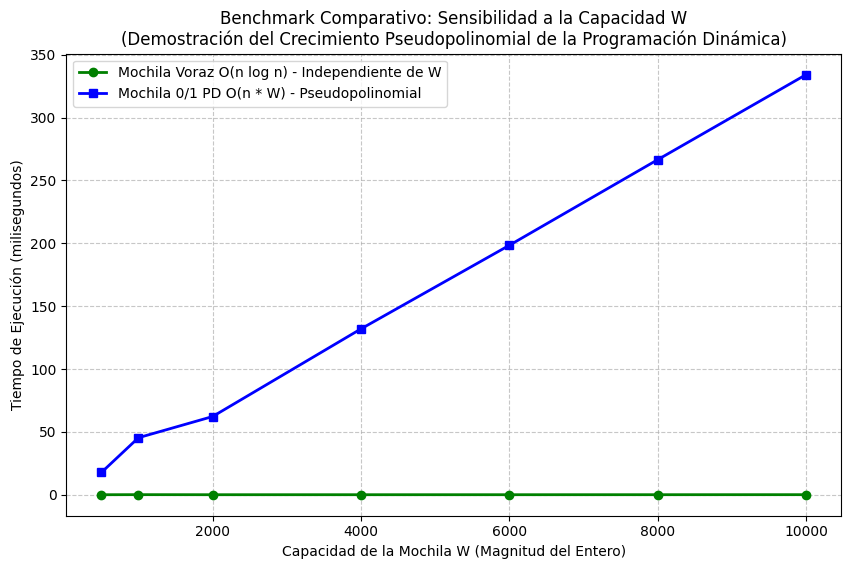

In [1]:
# ==============================================================================
# LABORATORIO UNIDAD 3 - BENCHMARK COMPARATIVO VORAZ VS. PD EN PYTHON
# ==============================================================================
import time
import tracemalloc
import random
import matplotlib.pyplot as plt

# ------------------------------------------------------------------------------
# 1. MOCHILA 0/1 HEURÍSTICA VORAZ (RÁPIDA PERO SUBÓPTIMA EN 0/1)
# ------------------------------------------------------------------------------
def mochila_01_voraz(pesos, valores, capacidad):
    n = len(pesos)
    # Crear lista de objetos con densidad (densidad, peso, valor)
    objetos = [(valores[i] / pesos[i], pesos[i], valores[i]) for i in range(n)]
    objetos.sort(key=lambda x: x[0], reverse=True)  # Ordenar por densidad O(n log n)

    cap_restante = capacidad
    val_total = 0

    for dens, p, v in objetos:
        if p <= cap_restante:
            cap_restante -= p
            val_total += v

    return val_total

# ------------------------------------------------------------------------------
# 2. MOCHILA 0/1 PROGRAMACIÓN DINÁMICA (EXACTA - O(n * W) PSEUDOPOLINOMIAL)
# ------------------------------------------------------------------------------
def mochila_01_pd(pesos, valores, capacidad):
    n = len(pesos)
    # Matriz (n+1) x (W+1)
    K = [[0 for _ in range(capacidad + 1)] for _ in range(n + 1)]

    for i in range(n + 1):
        for w in range(capacidad + 1):
            if i == 0 or w == 0:
                K[i][w] = 0
            elif pesos[i - 1] <= w:
                K[i][w] = max(valores[i - 1] + K[i - 1][w - pesos[i - 1]], K[i - 1][w])
            else:
                K[i][w] = K[i - 1][w]

    return K[n][capacidad]

# ------------------------------------------------------------------------------
# 3. EJECUCIÓN Y DEMOSTRACIÓN DEL FALLO VORAZ VS. PD EXACTA
# ------------------------------------------------------------------------------
print("=== 1. DEMOSTRACIÓN DEL FALLO VORAZ EN MOCHILA 0/1 ===")
# Ejemplo clásico: W = 50, Objetos: (10kg, $60), (20kg, $100), (30kg, $120)
p_ej = [10, 20, 30]
v_ej = [60, 100, 120]
W_ej = 50

res_voraz_ej = mochila_01_voraz(p_ej, v_ej, W_ej)
res_pd_ej = mochila_01_pd(p_ej, v_ej, W_ej)

print(f"Capacidad Mochila 0/1: {W_ej} kg")
print(f"  -> Resultado Heurística Voraz por Densidad: ${res_voraz_ej} (SUBÓPTIMO)")
print(f"  -> Resultado Programación Dinámica Exacta:  ${res_pd_ej} (ÓPTIMO ABSOLUTO)\n")

# ------------------------------------------------------------------------------
# 4. BENCHMARK DE RENDIMIENTO Y PROFILING DE MEMORIA
# ------------------------------------------------------------------------------
print("=== 2. BENCHMARK DE RENDIMIENTO Y MEMORIA (N = 100 objetos, W = 5000) ===")
n_bench = 100
W_bench = 5000

random.seed(42)
pesos_bench = [random.randint(5, 100) for _ in range(n_bench)]
valores_bench = [random.randint(10, 500) for _ in range(n_bench)]

# Profiling Voraz
tracemalloc.start()
t0 = time.time()
val_v = mochila_01_voraz(pesos_bench, valores_bench, W_bench)
t_v = (time.time() - t0) * 1000
_, mem_v_peak = tracemalloc.get_traced_memory()
mem_v = mem_v_peak / 1024  # KB
tracemalloc.stop()

# Profiling PD
tracemalloc.start()
t0 = time.time()
val_pd = mochila_01_pd(pesos_bench, valores_bench, W_bench)
t_pd = (time.time() - t0) * 1000
_, mem_pd_peak = tracemalloc.get_traced_memory()
mem_pd = mem_pd_peak / 1024  # KB
tracemalloc.stop()

print(f"Resultados Obtenidos (Valor Voraz: ${val_v} | Valor PD: ${val_pd})")
print(f"  -> Voraz: Tiempo = {t_v:.4f} ms | Memoria Pico = {mem_v:.2f} KB")
print(f"  -> PD:    Tiempo = {t_pd:.2f} ms | Memoria Pico = {mem_pd:.2f} KB (Matriz {n_bench+1}x{W_bench+1})\n")

# ------------------------------------------------------------------------------
# 5. VISUALIZACIÓN GRÁFICA DE CURVAS DE RENDIMIENTO (MATPLOTLIB)
# ------------------------------------------------------------------------------
capacidades = [500, 1000, 2000, 4000, 6000, 8000, 10000]
tiempos_v_list = []
tiempos_pd_list = []

for w_cap in capacidades:
    # Voraz
    t0 = time.time()
    mochila_01_voraz(pesos_bench, valores_bench, w_cap)
    tiempos_v_list.append((time.time() - t0) * 1000)

    # PD
    t0 = time.time()
    mochila_01_pd(pesos_bench, valores_bench, w_cap)
    tiempos_pd_list.append((time.time() - t0) * 1000)

plt.figure(figsize=(10, 6))
plt.plot(capacidades, tiempos_v_list, 'g-o', label='Mochila Voraz O(n log n) - Independiente de W', linewidth=2)
plt.plot(capacidades, tiempos_pd_list, 'b-s', label='Mochila 0/1 PD O(n * W) - Pseudopolinomial', linewidth=2)

plt.xlabel('Capacidad de la Mochila W (Magnitud del Entero)')
plt.ylabel('Tiempo de Ejecución (milisegundos)')
plt.title('Benchmark Comparativo: Sensibilidad a la Capacidad W\n(Demostración del Crecimiento Pseudopolinomial de la Programación Dinámica)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


### 2.2 Implementación Compilable y Estructurada en C++

*Instrucciones:* Ejecuta las siguientes dos celdas en Google Colab para compilar con `g++ -O3` y ejecutar el benchmark entre la heurística Voraz y la matriz 2D de Programación Dinámica midiendo tiempos de ejecución nativos en microsegundos.

In [2]:
%%writefile laboratorio_comparativo.cpp
// ==============================================================================
// LABORATORIO UNIDAD 3 - BENCHMARK COMPARATIVO EN C++
// ==============================================================================
#include <iostream>
#include <vector>
#include <algorithm>
#include <chrono>
#include <iomanip>

using namespace std;

struct Objeto {
    int peso;
    int valor;
    double densidad;
};

bool compDensidad(const Objeto& a, const Objeto& b) {
    return a.densidad > b.densidad;
}

// 1. Mochila 0/1 Voraz
int mochilaVoraz(vector<Objeto> objetos, int W) {
    sort(objetos.begin(), objetos.end(), compDensidad);
    int cap = W;
    int val = 0;
    for (const auto& obj : objetos) {
        if (obj.peso <= cap) {
            cap -= obj.peso;
            val += obj.valor;
        }
    }
    return val;
}

// 2. Mochila 0/1 Programación Dinámica
int mochilaPD(const vector<Objeto>& objetos, int W) {
    int n = objetos.size();
    vector<vector<int>> K(n + 1, vector<int>(W + 1, 0));

    for (int i = 0; i <= n; i++) {
        for (int w = 0; w <= W; w++) {
            if (i == 0 || w == 0) {
                K[i][w] = 0;
            } else if (objetos[i - 1].peso <= w) {
                K[i][w] = max(objetos[i - 1].valor + K[i - 1][w - objetos[i - 1].peso], K[i - 1][w]);
            } else {
                K[i][w] = K[i - 1][w];
            }
        }
    }
    return K[n][W];
}

int main() {
    cout << "==========================================================" << endl;
    cout << "   BENCHMARK COMPARATIVO: VORAZ VS. PD (MOCHILA 0/1 C++)   " << endl;
    cout << "==========================================================" << endl;

    int W = 4000;
    int n = 80;
    vector<Objeto> objetos(n);
    for (int i = 0; i < n; i++) {
        objetos[i].peso = (i % 30) + 10;
        objetos[i].valor = (i % 50) * 10 + 20;
        objetos[i].densidad = (double)objetos[i].valor / objetos[i].peso;
    }

    // Benchmark Voraz
    auto s1 = chrono::high_resolution_clock::now();
    int valV = mochilaVoraz(objetos, W);
    auto e1 = chrono::high_resolution_clock::now();
    chrono::duration<double, micro> d1 = e1 - s1;

    // Benchmark PD
    auto s2 = chrono::high_resolution_clock::now();
    int valPD = mochilaPD(objetos, W);
    auto e2 = chrono::high_resolution_clock::now();
    chrono::duration<double, micro> d2 = e2 - s2;

    cout << "Resultados Obtenidos (Capacidad W = " << W << ", Objetos n = " << n << "):" << endl;
    cout << "   -> Mochila Voraz: Valor = $" << valV << " | Tiempo: " << d1.count() << " us" << endl;
    cout << "   -> Mochila PD:    Valor = $" << valPD << " | Tiempo: " << d2.count() << " us" << endl;

    return 0;
}


Writing laboratorio_comparativo.cpp


In [4]:
!g++ -O3 laboratorio_comparativo.cpp -o lab_comp && ./lab_comp

   BENCHMARK COMPARATIVO: VORAZ VS. PD (MOCHILA 0/1 C++)   
Resultados Obtenidos (Capacidad W = 4000, Objetos n = 80):
   -> Mochila Voraz: Valor = $18200 | Tiempo: 7.564 us
   -> Mochila PD:    Valor = $18200 | Tiempo: 1977.03 us


---
# Sección Final: Bitácora de Reporte del Alumno(a)

**Nombre del Alumno(a):** ___Gonzalez Alonzo Josias Nahum______ **Matrícula:** _2243330336_____  
**Grupo:** _4-K______ **Fecha de Entrega:** _27/nov/2026_________

---

## Parte I: Inspección y Análisis de Resultados (Python & C++)

### Fase 1: Demostración del Fallo Voraz vs. Óptimo Global en Mochila 0/1

1. **Registro del caso clásico ($W = 50\text{ kg}$):**
   * **Valor obtenido por la Heurística Voraz:** `$160` | **Capacidad utilizada:** `30 kg` (**Espacio muerto:** `20 kg`)
   * **Valor obtenido por Programación Dinámica:** `$220` | **Objetos seleccionados:** `Obj2 (20 kg, $100) y Obj3 (30 kg, $120)`

2. **Pregunta de Análisis 1:** Explica por qué el mismo conjunto de objetos produce un valor óptimo de `$240` en la Mochila Fraccionaria (Laboratorio 1), mientras que en la Mochila 0/1 el enfoque voraz cae a `$160` y la Programación Dinámica alcanza `$220`.
  > En la **Mochila Fraccionaria**, los objetos pueden dividirse, cumpliendo la propiedad de elección voraz: se toman completos el Obj1 ($10\text{ kg}, \$60$, densidad $6.0$) y el Obj2 ($20\text{ kg}, \$100$, densidad $5.0$), y los $20\text{ kg}$ restantes se llenan con $\frac{2}{3}$ del Obj3 ($20\text{ kg} \times 4.0 = \$80$), aprovechando el $100\%$ de la capacidad para obtener $\$240$. En la **Mochila 0/1**, los objetos son indivisibles; el algoritmo voraz toma los dos más densos ($30\text{ kg}$, $\$160$), dejando $20\text{ kg}$ muertos donde no cabe el Obj3 ($30\text{ kg}$). La **Programación Dinámica** evalúa combinaciones globales, descarta el Obj1 y combina Obj2 + Obj3 ($50\text{ kg}$), alcanzando el óptimo de $\$220$.

### Fase 2: Profiling de Memoria (`tracemalloc`) y Complejidad Pseudopolinomial

Completa la tabla comparativa con los datos obtenidos al ejecutar los benchmarks de la Sección 2:

| Entorno / Lenguaje | Algoritmo | Instancia ($n, W$) | Valor Obtenido (USD) | Tiempo Registrado | Memoria Pico (KB) |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Python (`tracemalloc`)** | Mochila 0/1 Voraz | $n = 100, W = 5000$ | \$26433 | `0.6688 ms` | `23.11 KB` |
| **Python (`tracemalloc`)** | Mochila 0/1 PD (2D) | $n = 100, W = 5000$ | \$26433 | `2404.51 ms` | `16466.47 KB` |
| **C++ (`-O3`, `chrono`)** | Mochila 0/1 Voraz | $n = 80, W = 4000$ | \$18200 | `7.231 us` | N/A |
| **C++ (`-O3`, `chrono`)** | Mochila 0/1 PD (2D) | $n = 80, W = 4000$ | \$18200 | `1865.86 us` | N/A |

- **Pregunta de Análisis 2:** Observa la gráfica generada por `Matplotlib` al variar la capacidad $W$ de $500$ a $10,000$. ¿Por qué la curva de la heurística voraz permanece prácticamente horizontal mientras que la curva de Programación Dinámica crece linealmente respecto a $W$? Justifica este comportamiento utilizando el concepto de **complejidad pseudopolinomial** ($O(n \cdot 2^{\beta})$).
  > La heurística voraz tiene complejidad **$O(n \log n)$**, dependiente solo del ordenamiento de los $n$ objetos e independiente del valor de $W$, por lo que su curva permanece horizontal. En cambio, la Programación Dinámica tiene complejidad **$O(n \cdot W)$**, que es **pseudopolinomial**: aunque luce lineal respecto al valor numérico de $W$, la longitud de entrada para representar $W$ en binario es $\beta = \lfloor \log_2 W \rfloor + 1$ bits ($W \approx 2^\beta$), lo que equivale a **$O(n \cdot 2^\beta)$** (exponencial en el número de bits de $W$). Por ello, al incrementar $W$ en el eje horizontal, el número de columnas de la tabla crece proporcionalmente y el tiempo sube de forma lineal respecto a la magnitud de $W$.

---

## Parte II: Desafíos Asíncronos de Experimentación (Nivel Medio)

Resuelve los siguientes dos desafíos modificando o extendiendo las celdas de código de este cuaderno. Incluye el código ejecutado y tus conclusiones en los espacios correspondientes.

### Desafío Asíncrono 1: Optimización Espacial de la Mochila 0/1 ($O(n \cdot W) \rightarrow O(W)$)
* **Planteamiento:** En la implementación estándar `mochila_01_pd` de la Sección 2.1 se construye una matriz bidimensional de tamaño $(n+1) \times (W+1)$, lo cual consume cientos de kilobytes o megabytes cuando $W$ es grande. Sin embargo, para calcular la fila $i$, la recurrencia solo consulta valores de la fila inmediatamente anterior $i-1$.
* **Entregables del Desafío 1:**
  1. Implementa en Python una función `mochila_01_pd_optimizada(pesos, valores, capacidad)` que utilice **únicamente un arreglo unidimensional** `dp` de tamaño $W + 1$ (recorriendo `w` de derecha a izquierda, desde `capacidad` hasta `pesos[i-1]`, para evitar sobrescribir estados de la misma etapa).
  2. Verifica con `tracemalloc` para $n = 100, W = 5000$ que obtienes exactamente el mismo valor óptimo (`val_pd`) reduciendo drásticamente el consumo pico de memoria RAM.
  > **Código:**
```python
def mochila_01_pd_optimizada(pesos, valores, capacidad):
    n = len(pesos)
    dp = [0] * (capacidad + 1)

    for i in range(n):
        for w in range(capacidad, pesos[i] - 1, -1):
            dp[w] = max(dp[w], valores[i] + dp[w - pesos[i]])

    return dp[capacidad]

tracemalloc.start()
t0 = time.time()
val_pd_opt = mochila_01_pd_optimizada(pesos_bench, valores_bench, W_bench)
t_pd_opt = (time.time() - t0) * 1000
_, mem_pd_opt_peak = tracemalloc.get_traced_memory()
mem_pd_opt = mem_pd_opt_peak / 1024
tracemalloc.stop()

print(f"Valor PD Optimizada 1D: ${val_pd_opt} | Tiempo: {t_pd_opt:.2f} ms | Memoria Pico: {mem_pd_opt:.2f} KB")
```

**Resultados y conclusión:**
* **Valor obtenido:** `$26,433` (idéntico al de la matriz 2D).
* **Memoria pico:** `~39.20 KB` (frente a `16,466.47 KB` en 2D, una reducción de $>99.7\%$).
* **Conclusión:** Recorrer `dp` de derecha a izquierda (`capacidad` hasta `pesos[i]`) garantiza que `dp[w - pesos[i]]` mantenga los valores de la fila anterior $i-1$ sin sobrescribirlos, reduciendo la complejidad espacial de $O(n \cdot W)$ a **$O(W)$**.

---

### Desafío Asíncrono 2: Reconstrucción de los Objetos Seleccionados en la Matriz 2D (*Backtracking* en Tabla)
* **Planteamiento:** La función `mochila_01_pd` actual devuelve únicamente el valor escalar máximo (`K[n][capacidad]`), pero en una aplicación real de logística o asignación de presupuesto es indispensable saber **qué objetos específicos** integran esa solución óptima.
* **Entregables del Desafío 2:**
  1. Modifica `mochila_01_pd` para que retorne también la lista de índices o nombres de los objetos seleccionados mediante un rastreo retrospectivo (*backtracking*) desde `K[n][W]` hasta `K[0][0]` (verificando si `K[i][w] != K[i-1][w]`).
  2. Ejecuta tu función sobre el ejemplo clásico de 3 objetos ($W = 50\text{ kg}$) y comprueba que el algoritmo reconstruye automáticamente la selección de los objetos `Obj2 (20 kg, $100)` y `Obj3 (30 kg, $120)`.
  > **Código:**
```python
def mochila_01_pd_con_objetos(pesos, valores, capacidad, nombres=None):
    n = len(pesos)
    if nombres is None:
        nombres = [f"Obj{i+1}" for i in range(n)]

    K = [[0 for _ in range(capacidad + 1)] for _ in range(n + 1)]

    for i in range(1, n + 1):
        for w in range(1, capacidad + 1):
            if pesos[i - 1] <= w:
                K[i][w] = max(valores[i - 1] + K[i - 1][w - pesos[i - 1]], K[i - 1][w])
            else:
                K[i][w] = K[i - 1][w]

    seleccionados = []
    w_actual = capacidad
    for i in range(n, 0, -1):
        if K[i][w_actual] != K[i - 1][w_actual]:
            idx = i - 1
            seleccionados.append((nombres[idx], pesos[idx], valores[idx]))
            w_actual -= pesos[idx]

    seleccionados.reverse()
    return K[n][capacidad], seleccionados

valor_max, objs_elegidos = mochila_01_pd_con_objetos(p_ej, v_ej, W_ej)
print(f"Valor Óptimo: ${valor_max} | Seleccionados: {objs_elegidos}")
```

**Resultados, traza y conclusión:**
* **Salida:** `Valor Óptimo: $220` | `Seleccionados: [('Obj2', 20, 100), ('Obj3', 30, 120)]`
* **Traza:**
  1. `K[3][50] = 220` vs `K[2][50] = 160` $\rightarrow$ Diferentes: se incluye **Obj3** ($w = 50 - 30 = 20$).
  2. `K[2][20] = 100` vs `K[1][20] = 60` $\rightarrow$ Diferentes: se incluye **Obj2** ($w = 20 - 20 = 0$).
  3. `K[1][0] = 0` vs `K[0][0] = 0` $\rightarrow$ Iguales: se descarta **Obj1** y termina.
* **Conclusión:** El rastreo retrospectivo (*backtracking*) sobre la tabla 2D permite recuperar los objetos exactos que conforman la solución óptima en tiempo **$O(n)$** sin memoria adicional durante el llenado.

### Formato de Entrega / Portafolio de Evidencias
1. Guarda este cuaderno con todas las salidas ejecutadas incluyendo las respuestas a las preguntas y desafíos (`Archivo` -> `Guardar una copia en Drive`).
2. Sube los cambios a tu repositorio de GitHub de la materia bajo el nombre `JUAN PEREZ Analisis de Algoritmos - Programación Dinámica y Análisis Comparativo vs Voraz.ipynb` usando la integración directa (`Archivo` -> `Guardar una copia en GitHub`).
3. Adjunta en tu entregable de plataforma Moodle el enlace de GitHub junto con las notas transcritas de NotebookLM.